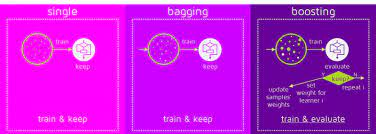
## Understanding the Business Problem
TalkingData is a Chinese big data company, and one of their areas of expertise is mobile advertisements.

In mobile advertisements, click fraud is a major source of losses. Click fraud is the practice of repeatedly clicking on an advertisement hosted on a website with the intention of generating revenue for the host website or draining revenue from the advertiser.

In this case, TalkingData happens to be serving the advertisers (their clients). TalkingData cover a whopping approx. 70% of the active mobile devices in China, of which 90% are potentially fraudulent (i.e. the user is actually not going to download the app after clicking).

You can imagine the amount of money they can help clients save if they are able to predict whether a given click is fraudulent (or equivalently, whether a given click will result in a download).

Their current approach to solve this problem is that they've generated a blacklist of IP addresses - those IPs which produce lots of clicks, but never install any apps. Now, they want to try some advanced techniques to predict the probability of a click being genuine/fraud.

In this problem, we will use the features associated with clicks, such as IP address, operating system, device type, time of click etc. to predict the probability of a click being fraud.



# Project on Bagging and Boosting ensemble model:


**The data contains observations of about 240 million clicks, and whether a given click resulted in a download or not (1/0):**

The detailed data dictionary is mentioned here:
- ```ip```: ip address of click.
- ```app```: app id for marketing.
- ```device```: device type id of user mobile phone (e.g., iphone 6 plus, iphone 7, huawei mate 7, etc.)
- ```os```: os version id of user mobile phone
- ```channel```: channel id of mobile ad publisher
- ```click_time```: timestamp of click (UTC)
- ```attributed_time```: if user download the app for after clicking an ad, this is the time of the app download
- ```is_attributed```: the target that is to be predicted, indicating the app was downloaded

Let's try finding some useful trends in the data.

    **1. Explore the dataset for anomalies and missing values and take corrective actions if necessary.**

    **2. Which column has maximum number of unique values present among all the available columns**

    **3. Use an appropriate technique to get rid of all the apps that are very rare (say which comprise of less                than 20% clicks) and plot the rest..** 

    **4. By using Pandas derive new features such as - 'day_of_week' , 'day_of_year' , 'month' , and 'hour' as                  float/int datatypes using the 'click_time' column . Add the newly derived columns in original dataset.**

    **5. Divide the data into training and testing subsets into 80:20 ratio(Train_data = 80% , Testing_data = 20%) and
         check the average download rates('is_attributed') for train and test data, scores should be comparable.**

    **6. Apply XGBoostClassifier with default parameters on training data and make first 10 prediction for Test data.          NOTE: Use y_pred = model.predict_proba(X_test) since we need probabilities to compute AUC.** 

    **7. On evaluating the predictions made by the model what is the AUC/ROC score with default hyperparameters.**

    **8. Compute feature importance score and name the top 5 features/columns .**
    
    **9. Apply BaggingClassifier with base_estimator LogisticRegression and compute AUC/ROC score.
    
    **10.  On the basis of AUC/ROC score which one will you choose from BaggingClassifier and XGBoostClassifier and why? What does AUC/ROC score signifies?
    
    **11.  What is the accuracy for BaggingClassifier and XGBoostClassifier?()
 ### All the Best!!!

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import zscore
import warnings
warnings.filterwarnings('ignore')
from sklearn import metrics

In [2]:
df = pd.read_csv('talking_data.csv')
df.head()

,ip,app,device,os,channel,click_time,attributed_time,is_attributed
0,87540,12,1,13,497,2017-11-07 09:30:38,NaN,0
1,105560,25,1,17,259,2017-11-07 13:40:27,NaN,0
2,101424,12,1,19,212,2017-11-07 18:05:24,NaN,0
3,94584,13,1,13,477,2017-11-07 04:58:08,NaN,0
4,68413,12,1,1,178,2017-11-09 09:00:09,NaN,0


In [3]:
print("Diamensions of the data : ",df.shape)

Diamensions of the data :  (100000, 8)


In [4]:
feature_names = df.columns.values
print("Feature names : ",feature_names)

Feature names :  ['ip' 'app' 'device' 'os' 'channel' 'click_time' 'attributed_time'
 'is_attributed']


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 8 columns):
 #   Column           Non-Null Count   Dtype 
---  ------           --------------   ----- 
 0   ip               100000 non-null  int64 
 1   app              100000 non-null  int64 
 2   device           100000 non-null  int64 
 3   os               100000 non-null  int64 
 4   channel          100000 non-null  int64 
 5   click_time       100000 non-null  object
 6   attributed_time  227 non-null     object
 7   is_attributed    100000 non-null  int64 
dtypes: int64(6), object(2)
memory usage: 6.1+ MB


**1. Explore the dataset for anomalies and missing values and take corrective actions if necessary.**

In [6]:
df.isnull().sum()

ip                     0
app                    0
device                 0
os                     0
channel                0
click_time             0
attributed_time    99773
is_attributed          0
dtype: int64

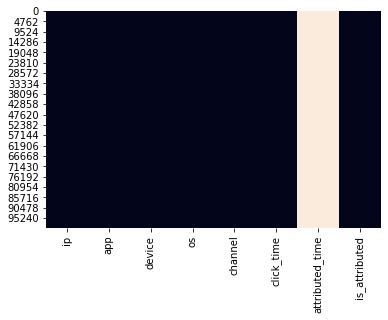

In [7]:
#Missing values map, missing values can be
    #found as white dots along each column,
    #here there are no missing values
sns.heatmap(df.isnull(), cbar=False)
plt.show()

- attributed_time has a high number of missing values

In [8]:
df1 = df.drop(['attributed_time'], axis=1)

**2. Which column has maximum number of unique values present among all the available columns**

In [9]:
df1.nunique()

ip               34857
app                161
device             100
os                 130
channel            161
click_time       80350
is_attributed        2
dtype: int64

- The feature click_time has the maximum number of unique values among the features

**3)Use an appropriate technique to get rid of all the apps that are very rare (say which comprise of less than 20% clicks) and plot the rest** 

In [10]:
frequent_apps=df1.groupby('app').size().reset_index(name='count')
frequent_apps=frequent_apps[frequent_apps['count'] > frequent_apps['count'].quantile(0.2)]
frequent_apps=frequent_apps.merge(df1,on='app',how='inner')
frequent_apps.head()

,app,count,ip,device,os,channel,click_time,is_attributed
0,1,3135,17059,1,17,135,2017-11-09 01:17:58,0
1,1,3135,52432,1,13,115,2017-11-07 17:22:52,0
2,1,3135,89242,1,27,124,2017-11-07 09:37:21,0
3,1,3135,123994,1,19,101,2017-11-09 14:27:57,0
4,1,3135,34067,1,15,134,2017-11-07 15:06:06,0


In [11]:
frequent_apps.shape


(99961, 8)

In [12]:
frequent_apps.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 99961 entries, 0 to 99960
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   app            99961 non-null  int64 
 1   count          99961 non-null  int64 
 2   ip             99961 non-null  int64 
 3   device         99961 non-null  int64 
 4   os             99961 non-null  int64 
 5   channel        99961 non-null  int64 
 6   click_time     99961 non-null  object
 7   is_attributed  99961 non-null  int64 
dtypes: int64(7), object(1)
memory usage: 6.9+ MB


In [13]:
df1.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 7 columns):
 #   Column         Non-Null Count   Dtype 
---  ------         --------------   ----- 
 0   ip             100000 non-null  int64 
 1   app            100000 non-null  int64 
 2   device         100000 non-null  int64 
 3   os             100000 non-null  int64 
 4   channel        100000 non-null  int64 
 5   click_time     100000 non-null  object
 6   is_attributed  100000 non-null  int64 
dtypes: int64(6), object(1)
memory usage: 5.3+ MB


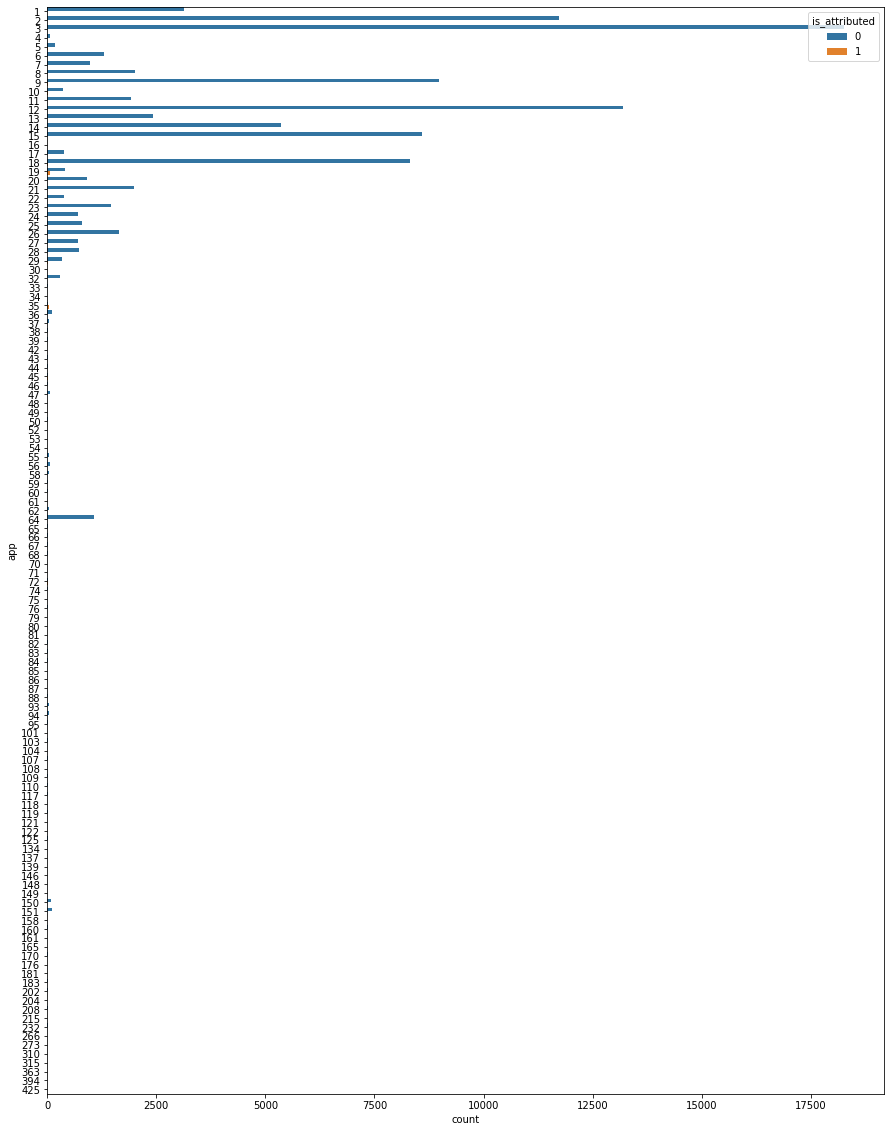

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(15,20))
sns.countplot(y="app", hue="is_attributed", data=frequent_apps);

**4. By using Pandas derive new features such as - 'day_of_week' , 'day_of_year' , 'month' , and 'hour' as    float/int datatypes using the 'click_time' column . Add the newly derived columns in original dataset.**
 

In [15]:
# Converting string data into temporal feature
df1['date_time'] = pd.to_datetime(df1['click_time'])

In [16]:
df1.head()

,ip,app,device,os,channel,click_time,is_attributed,date_time
0,87540,12,1,13,497,2017-11-07 09:30:38,0,2017-11-07 09:30:38
1,105560,25,1,17,259,2017-11-07 13:40:27,0,2017-11-07 13:40:27
2,101424,12,1,19,212,2017-11-07 18:05:24,0,2017-11-07 18:05:24
3,94584,13,1,13,477,2017-11-07 04:58:08,0,2017-11-07 04:58:08
4,68413,12,1,1,178,2017-11-09 09:00:09,0,2017-11-09 09:00:09


In [17]:
df1['Day_of_week'] = df1['date_time'].dt.day_name()
df1['Day_of_year'] = df1['date_time'].dt.dayofyear
df1['Month'] = df1['date_time'].dt.month
df1['Hour'] = df1['date_time'].dt.hour


df1.head()

,ip,app,device,os,channel,click_time,is_attributed,date_time,Day_of_week,Day_of_year,Month,Hour
0,87540,12,1,13,497,2017-11-07 09:30:38,0,2017-11-07 09:30:38,Tuesday,311,11,9
1,105560,25,1,17,259,2017-11-07 13:40:27,0,2017-11-07 13:40:27,Tuesday,311,11,13
2,101424,12,1,19,212,2017-11-07 18:05:24,0,2017-11-07 18:05:24,Tuesday,311,11,18
3,94584,13,1,13,477,2017-11-07 04:58:08,0,2017-11-07 04:58:08,Tuesday,311,11,4
4,68413,12,1,1,178,2017-11-09 09:00:09,0,2017-11-09 09:00:09,Thursday,313,11,9


In [18]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 12 columns):
 #   Column         Non-Null Count   Dtype         
---  ------         --------------   -----         
 0   ip             100000 non-null  int64         
 1   app            100000 non-null  int64         
 2   device         100000 non-null  int64         
 3   os             100000 non-null  int64         
 4   channel        100000 non-null  int64         
 5   click_time     100000 non-null  object        
 6   is_attributed  100000 non-null  int64         
 7   date_time      100000 non-null  datetime64[ns]
 8   Day_of_week    100000 non-null  object        
 9   Day_of_year    100000 non-null  int64         
 10  Month          100000 non-null  int64         
 11  Hour           100000 non-null  int64         
dtypes: datetime64[ns](1), int64(9), object(2)
memory usage: 9.2+ MB


In [19]:
from sklearn.preprocessing import LabelEncoder

labelencoder = LabelEncoder()
df1['Weekday'] = labelencoder.fit_transform(df1['Day_of_week'])


In [20]:
df1.drop(['click_time'], axis=1,inplace=True)
df1.drop(['date_time'], axis=1,inplace=True)
df1.drop(['Day_of_week'], axis=1,inplace=True)

**5. Divide the data into training and testing subsets into 80:20 ratio(Train_data = 80% , Testing_data = 20%) and check the average download rates('is_attributed') for train and test data, scores should be comparable.**
 

In [21]:
from sklearn.model_selection import train_test_split
train, val = train_test_split(df1, test_size=0.20)

In [22]:
train_x = train.drop(['is_attributed'], axis = 1)
train_y = train['is_attributed']             # output of the training data

val_x = val.drop(['is_attributed'], axis = 1)
val_y = val['is_attributed']

In [23]:
train_y.mean()

0.0022625

In [24]:
val_y.mean()

0.0023

In [25]:
(0.00225/0.00235)*100

95.74468085106382

**6. Apply XGBoostClassifier with default parameters on training data and make first 10 prediction for Test data.  NOTE: Use y_pred = model.predict_proba(X_test) since we need probabilities to compute AUC.** 
 

In [26]:
from xgboost import XGBClassifier

xgb = XGBClassifier()

In [27]:
model = xgb.fit(train_x, train_y)

test_pred = model.predict(val_x)
xgb_score=model.score(val_x, val_y)
print("The Xgboost Ensemble model accuracy is {}".format(xgb_score))


[09:10:44] WARNING: /Users/travis/build/dmlc/xgboost/src/learner.cc:1095: Starting in XGBoost 1.3.0, the default evaluation metric used with the objective 'binary:logistic' was changed from 'error' to 'logloss'. Explicitly set eval_metric if you'd like to restore the old behavior.
The Xgboost Ensemble model accuracy is 0.99765


The confusion matrix of Xgboost Ensemble model is
[[19943    11]
 [   36    10]]


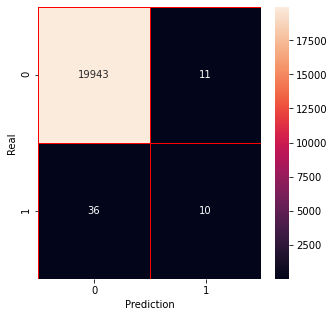

In [28]:
print("The confusion matrix of Xgboost Ensemble model is")
print(metrics.confusion_matrix(val_y,test_pred))

#confusion metrics visualization
f, ax = plt.subplots(figsize=(5,5))
sns.heatmap(metrics.confusion_matrix(val_y,test_pred), annot=True, linewidths=0.5, linecolor="red", fmt=".0f", ax=ax)
plt.xlabel("Prediction")
plt.ylabel("Real")
plt.show()

In [29]:
model = xgb.fit(train_x, train_y)
y_pred = model.predict_proba(val_x)
y_pred

[09:10:52] WARNING: /Users/travis/build/dmlc/xgboost/src/learner.cc:1095: Starting in XGBoost 1.3.0, the default evaluation metric used with the objective 'binary:logistic' was changed from 'error' to 'logloss'. Explicitly set eval_metric if you'd like to restore the old behavior.


array([[9.9972928e-01, 2.7074749e-04],
       [9.9978465e-01, 2.1536114e-04],
       [9.9886507e-01, 1.1349136e-03],
       ...,
       [9.9999398e-01, 6.0102484e-06],
       [9.9997336e-01, 2.6663829e-05],
       [9.9836195e-01, 1.6380340e-03]], dtype=float32)

**7. On evaluating the predictions made by the model what is the AUC/ROC score with default hyperparameters.**

In [30]:
from sklearn.metrics import roc_auc_score

In [31]:
model = xgb.fit(train_x, train_y)
pred_y = model.predict_proba(val_x)
# keep probabilities for the positive outcome only
pred_y_1 = pred_y[:, 1]
# calculate scores
xg_auc = roc_auc_score(val_y, pred_y_1)
print(xg_auc)
# # calculate roc curves
# xg, xg_tpr, _ = roc_curve(val_y, ns_probs)
# # plot the roc curve for the model
# pyplot.plot(xg_fpr, xg_tpr, linestyle=‘--’, label=‘XGboost’)
# # axis labels
# plt.xlabel(‘False Positive Rate’)
# plt.ylabel(‘True Positive Rate’)
# # show the legend
# plt.legend()
# # show the plot
# plt.show()

[09:10:57] WARNING: /Users/travis/build/dmlc/xgboost/src/learner.cc:1095: Starting in XGBoost 1.3.0, the default evaluation metric used with the objective 'binary:logistic' was changed from 'error' to 'logloss'. Explicitly set eval_metric if you'd like to restore the old behavior.
0.9251626567191497


No handles with labels found to put in legend.


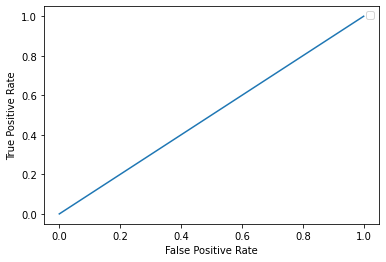

In [32]:
from sklearn.metrics import roc_curve
# calculate roc curves
ns_probs = [0 for _ in range(len(val_y))]

xg_fpr, xg_tpr, _ = roc_curve(val_y, ns_probs)
# plot the roc curve for the model
plt.plot(xg_fpr, xg_tpr)
# axis labels
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
# show the legend
plt.legend()
# show the plot
plt.show()

In [33]:
from sklearn.feature_selection import SelectPercentile
from sklearn.feature_selection import f_regression


# Write your solution here:
def percentile_k_features(df,k=20):

    X=df.iloc[:,:-1]
    y=df.iloc[:,-1]
    features=X.columns
    sp=SelectPercentile(f_regression,percentile=k)
    sp.fit_transform(X,y)
    imp_features=[features[i] for i in np.argsort(sp.scores_)[::-1]]
    return imp_features[:7]

**8. Compute feature importance score and name the top 5 features/columns .**

In [34]:
print("Feature importance scores : ")
model.get_booster().get_score(importance_type="gain")

Feature importance scores : 


{'device': 3.335461700377275,
 'ip': 1.0329649097392815,
 'Hour': 0.8709459846608173,
 'channel': 2.6724162416987176,
 'os': 1.0616184305704441,
 'Weekday': 0.9983904842854543,
 'app': 2.8278213863050907,
 'Day_of_year': 0.8288654822745454}

Top 5 important features are : device,app,channel,ip,os

**9. Apply BaggingClassifier with base_estimator LogisticRegression and compute AUC/ROC score.

In [35]:
from sklearn.ensemble import BaggingClassifier

bgcl = BaggingClassifier(n_estimators=10, max_samples= .7, bootstrap=True)
bgcl = bgcl.fit(train_x, train_y)
test_pred = bgcl.predict(val_x)
bgcl_score=bgcl.score(val_x, val_y)
print("The Bagging classifier model accuracy is {}".format(bgcl_score))


The Bagging classifier model accuracy is 0.9977


The confusion matrix of Bagging classifier model is
[[19947     7]
 [   39     7]]


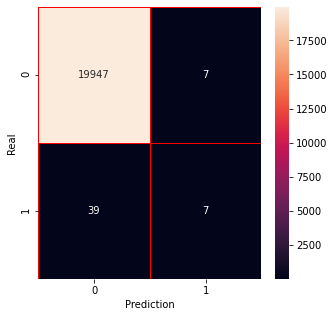

In [36]:
print("The confusion matrix of Bagging classifier model is")
print(metrics.confusion_matrix(val_y,test_pred))

#confusion metrics visualization
f, ax = plt.subplots(figsize=(5,5))
sns.heatmap(metrics.confusion_matrix(val_y,test_pred), annot=True, linewidths=0.5, linecolor="red", fmt=".0f", ax=ax)
plt.xlabel("Prediction")
plt.ylabel("Real")
plt.show()

In [37]:
from sklearn.metrics import roc_auc_score
model_bgcl = bgcl.fit(train_x, train_y)
pred_y = model.predict_proba(val_x)
# keep probabilities for the positive outcome only
pred_y_1 = pred_y[:, 1]
# calculate scores
bgcl_auc = roc_auc_score(val_y, pred_y_1)
print(bgcl_auc)

0.9251626567191497


No handles with labels found to put in legend.


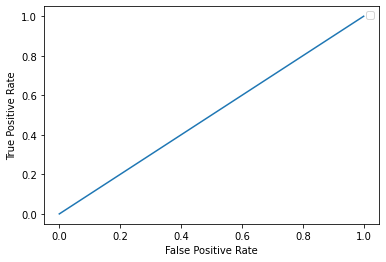

In [38]:
from sklearn.metrics import roc_curve
# calculate roc curves
ns_probs = [0 for _ in range(len(val_y))]

bgcl_fpr, bgcl_tpr, _ = roc_curve(val_y, ns_probs)
# plot the roc curve for the model
plt.plot(bgcl_fpr, bgcl_tpr)
# axis labels
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
# show the legend
plt.legend()
# show the plot
plt.show()

**10.  On the basis of AUC/ROC score which one will you choose from BaggingClassifier and XGBoostClassifier and why? What does AUC/ROC score signifies?**

Area under curve for Bagging classifier is higher than XGboost algorithm

AUC provides an aggregate measure of performance across all possible classification thresholds. One way of interpreting AUC is as the probability that the model ranks a random positive example more highly than a random negative example.

**11.  What is the accuracy for BaggingClassifier and XGBoostClassifier?()**

In [39]:
print("The Bagging classifier model accuracy is {}".format(bgcl_score))
print("The Xgboost Ensemble model accuracy is {}".format(xgb_score))

The Bagging classifier model accuracy is 0.9977
The Xgboost Ensemble model accuracy is 0.99765
